# [DEMO] Logical PPM — BB Gross Code

In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import json
import os
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display, Markdown, HTML
from benchmarks.logical_ops.bb_ppm_runner import available_workers
from lightstim.protocols.bb_ppm import BBPPMStep
from lightstim.qec_code.BB_code.ppm.shift import build_tour_de_gross_code, logical_shift_tableaus
from lightstim.qec_code.BB_code.ppm.lowering import BBPPMCompiler
from lightstim.qec_code.BB_code.ppm.native_reporting import export_basic_measurements
from lightstim.qec_code.BB_code.ppm.reporting import (
    format_logical_pauli, export_shift_and_native_catalogs,
    export_rotation_catalog, export_plan_report,
)

OUTPUT = ROOT / "benchmarks/logical_ops/results/bb_ppm_reports"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)


def display_path(path, *, base=OUTPUT):
    """Format printed paths relative to their stated base directory."""
    return Path(os.path.relpath(Path(path).resolve(), Path(base).resolve())).as_posix()


ROUNDS = 10
INITIAL_STATE = 'X'
FINAL_BASIS = 'X'
P_VALUES = (0.0005, 0.001, 0.002)
SHOTS_BY_P = {0.0005: 1000000, 0.001: 1000000, 0.002: 100000}
WORKER_PROCESSES = min(32, available_workers())
SAMPLE_SEED = 2026112404
NOISE_MODEL = 'circuit_level_with_idling'
# Selected on training samples, then frozen before the recorded validation runs.
DECODER_PARAMS = {'alpha': 0.8, 'gamma0': 0.5, 'gamma_dist_interval': (-0.1, 0.5), 'logging': False, 'num_sets': 600, 'pre_iter': 320, 'seed': 0, 'set_max_iter': 60, 'stop_nconv': 5, 'stopping_criterion': 'nconv'}
RUN_SAMPLING = False
RUN_DIR = ROOT / 'benchmarks/logical_ops/results/bb_ppm_y1_large_20261124'
RESULTS_PATH = (
    RUN_DIR / "results.csv" if RUN_SAMPLING else
    ROOT / "benchmarks/logical_ops/reference/bb_ppm/y1_large_20261124/results.csv"
)

print("Output folder:", display_path(OUTPUT, base=ROOT))
print("Result table:", display_path(RESULTS_PATH, base=ROOT))
print("Artifact paths below are relative to Output folder.")


Output folder: benchmarks/logical_ops/results/bb_ppm_reports
Result table: benchmarks/logical_ops/reference/bb_ppm/y1_large_20261124/results.csv
Artifact paths below are relative to Output folder.


## Cell 1 · 15 Basic LPU Measurements and Stabilizer Definitions

In [2]:
basic_rows = export_basic_measurements(OUTPUT / "stabilizer_definition", validate=True)
assert len(basic_rows) == 15
display(pd.DataFrame(basic_rows)[[
    "target", "lpu_mode", "vertex_checks", "cycle_checks", "edge_qubits",
    "modified_bb_checks", "validation_status",
]])
print("All 15 stabilizer definitions:", display_path(OUTPUT / "stabilizer_definition"))
print("All 15 measurement summaries:", display_path(OUTPUT / "stabilizer_definition" / "manifest.json"))


,target,lpu_mode,vertex_checks,cycle_checks,edge_qubits,modified_bb_checks,validation_status
0,X7,right,12,3,18,18,passed
1,Y7,full,23,19,47,36,passed
2,Z7,left,12,5,18,18,passed
3,X1,left,12,5,18,18,passed
4,X1 X7,full,23,19,47,36,passed
5,X1 Y7,full,23,19,47,54,passed
6,X1 Z7,left,12,5,18,36,passed
7,Y1,full,23,19,47,36,passed
8,Y1 X7,full,23,19,47,54,passed
9,Y1 Y7,full,23,19,47,72,passed


All 15 stabilizer definitions: stabilizer_definition
All 15 measurement summaries: stabilizer_definition/manifest.json


## Cell 2 · 36 Logical Shifts and 540 Native Measurements

In [3]:
from IPython.display import HTML

gross = build_tour_de_gross_code()
compiler = BBPPMCompiler(logical_shift_tableaus(gross))
catalogs = export_shift_and_native_catalogs(compiler, gross, OUTPUT)
shift_rows = catalogs["rows"]["shifts"]
native_rows = catalogs["rows"]["native_measurements"]
assert len(shift_rows) == 36 and len(native_rows) == 540
display(pd.DataFrame(shift_rows)[[
    "shift", "inverse_shift",
]])
native_table = pd.DataFrame(native_rows)
# Preview genuinely shifted entries; catalogue ordering is by Pauli string.
shifted_preview = native_table[(native_table["shift_x"] != 0) | (native_table["shift_y"] != 0)].head(10)
display(Markdown(f"Showing {len(shifted_preview)} examples out of {len(native_rows)} native measurements."))
display(HTML(shifted_preview[[
    "basic_measurement", "shift", "conjugated_pauli", "chronology",
]].rename(columns={
    "basic_measurement": "before shift",
    "conjugated_pauli": "after shift",
}).to_html(index=False)))
print("Distinct shifts:", len(shift_rows))
print("Native measurements:", len(native_rows))
for name, path in catalogs["paths"].items():
    print(f"{name}: {display_path(path)}")


,shift,inverse_shift
0,"x: 0, y: 0","x: 0, y: 0"
1,"x: 0, y: 1","x: 0, y: 5"
2,"x: 0, y: 2","x: 0, y: 4"
3,"x: 0, y: 3","x: 0, y: 3"
4,"x: 0, y: 4","x: 0, y: 2"
5,"x: 0, y: 5","x: 0, y: 1"
6,"x: 1, y: 0","x: 5, y: 0"
7,"x: 1, y: 1","x: 5, y: 5"
8,"x: 1, y: 2","x: 5, y: 4"
9,"x: 1, y: 3","x: 5, y: 3"


Showing 10 examples out of 540 native measurements.

before shift,shift,after shift,chronology
+X7,"x: 3, y: 5",+X12,"x: 3, y: 1 -> Measure(+X7) -> x: 3, y: 5"
+Z7,"x: 2, y: 4",+Z12,"x: 4, y: 2 -> Measure(+Z7) -> x: 2, y: 4"
+X7,"x: 5, y: 5",+X11,"x: 1, y: 1 -> Measure(+X7) -> x: 5, y: 5"
+X7,"x: 1, y: 5",+X11 X12,"x: 5, y: 1 -> Measure(+X7) -> x: 1, y: 5"
+Z7,"x: 1, y: 2",+Z11,"x: 5, y: 4 -> Measure(+Z7) -> x: 1, y: 2"
+X7,"x: 4, y: 1",+X10,"x: 2, y: 5 -> Measure(+X7) -> x: 4, y: 1"
+X7,"x: 4, y: 0",+X10 X11 X12,"x: 2, y: 0 -> Measure(+X7) -> x: 4, y: 0"
+Z7,"x: 2, y: 5",+Z10,"x: 4, y: 1 -> Measure(+Z7) -> x: 2, y: 5"
+Z7,"x: 5, y: 0",+Z10 Z12,"x: 1, y: 0 -> Measure(+Z7) -> x: 5, y: 0"
+Z7,"x: 0, y: 2",+Z10 Z11,"x: 0, y: 4 -> Measure(+Z7) -> x: 0, y: 2"


Distinct shifts: 36
Native measurements: 540
shifts_json: shifts/shifts.json
shifts_csv: shifts/shifts.csv
native_json: native_measurements/native_measurements.json
native_csv: native_measurements/native_measurements.csv


## Cell 3 · 245 Implementable Nontrivial Rotation Axes $A$

In [4]:
rotation_catalog = export_rotation_catalog(compiler, OUTPUT)
axis_rows = rotation_catalog["rows"]["axes"]
implementation_rows = rotation_catalog["rows"]["implementations"]
assert len(axis_rows) == 245 and len(implementation_rows) == 253
axis_preview = pd.DataFrame(axis_rows).head(10)
display(Markdown(f"Showing {len(axis_preview)} examples out of {len(axis_rows)} distinct available rotation axes A."))
display(HTML(axis_preview[[
    "axis", "implementation_count", "chosen_joint",
    "chosen_shift", "chosen_basic", "prepare", "readout", "forward_correction",
]].rename(columns={
    "axis": "axis (A)", "chosen_joint": "chosen_joint (Q₁A)",
}).to_html(index=False)))
print("Nontrivial Q1 A implementations:", len(implementation_rows))
print("Distinct nontrivial data rotation axes A:", len(axis_rows))
for name, path in rotation_catalog["paths"].items():
    print(f"{name}: {display_path(path)}")


Showing 10 examples out of 245 distinct available rotation axes A.

axis (A),implementation_count,chosen_joint (Q₁A),chosen_shift,chosen_basic,prepare,readout,forward_correction
+X7,3,+X1 X7,"x: 0, y: 0",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+Y7,3,+X1 Y7,"x: 0, y: 0",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A
+Z7,3,+X1 Z7,"x: 0, y: 0",+X1 Z7,Z1,Y1,r*m*s = +1: apply/track A
+Z6,1,+Z1 Z6,"x: 0, y: 5",+Z1,Y1,X1,r*m*s = +1: apply/track A
+Z6 X8 X11,1,+Z1 Z6 X8 X11,"x: 0, y: 5",+Z1 X7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Y8 X11,1,+Z1 Z6 Z7 Y8 X11,"x: 0, y: 5",+Z1 Y7,Y1,X1,r*m*s = +1: apply/track A
+Z6 Z7 Z8,1,+Z1 Z6 Z7 Z8,"x: 0, y: 5",+Z1 Z7,Y1,X1,r*m*s = +1: apply/track A
+X4 X6,1,+X1 X4 X6,"x: 5, y: 3",+X1,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 X7 X8 X10,1,+X1 X4 X6 X7 X8 X10,"x: 5, y: 3",+X1 X7,Z1,Y1,r*m*s = +1: apply/track A
+X4 X6 Y7 X8 Z9 X10 Z11,1,+X1 X4 X6 Y7 X8 Z9 X10 Z11,"x: 5, y: 3",+X1 Y7,Z1,Y1,r*m*s = +1: apply/track A


Nontrivial Q1 A implementations: 253
Distinct nontrivial data rotation axes A: 245
axes_json: rotation_axes/rotation_axes.json
axes_csv: rotation_axes/rotation_axes.csv
implementations_json: rotation_axes/rotation_implementations.json
implementations_csv: rotation_axes/rotation_implementations.csv


## Cell 4 · Bidirectional Search, Selected Path, and Full Operation Sequence

Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New and total counts refer to distinct Pauli operators.

**PPM 0 — target: +Y1**

This target requires no bidirectional search; the measurement plan is generated directly.

This target needs no Clifford search path.


The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage.

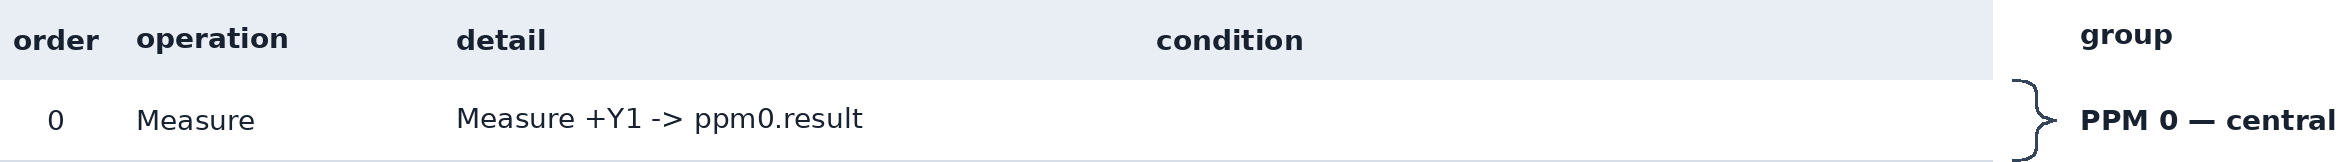

,step,measurements,shifts,frame_updates,output
0,0,1,0,0,ppm0.result


Compiled-plan SHA256: e1662e140019b044fe0813d908dc5aea18680cd5f0571fd6451453524982ffb3
plans_json: searches/plans.json
summary_csv: searches/plan_summary.csv
search_csv: searches/search_progress.csv
path_csv: searches/selected_paths.csv
operations_csv: searches/operations.csv


In [5]:
ppm_sequence = [BBPPMStep(((1, "Y"),))]
# Advanced input example:
# ppm_sequence = [BBPPMStep(((2, "X"), (7, "Z"), (12, "X")))]

plans = tuple(compiler.compile(step.targets, prefix=f"ppm{i}")
              for i, step in enumerate(ppm_sequence))
plan_report = export_plan_report(compiler, plans, OUTPUT)
from IPython.display import HTML

display(Markdown("Round 0 initializes the search. Each subsequent round expands the side with the smaller frontier. New and total counts refer to distinct Pauli operators."))
for step, plan in enumerate(plans):
    display(Markdown(f"**PPM {step} — target: {format_logical_pauli(plan.target)}**"))
    if plan.search_status == "cached":
        display(Markdown("This target reuses a cached path. The records below are from its original search; no new expansion was performed."))
    search_rows = [row for row in plan_report["rows"]["search"] if row["step"] == step]
    if search_rows:
        search_table = pd.DataFrame(search_rows)[[
            "round", "expanded_side", "target_new", "target_total",
            "native_new", "native_total", "connected", "meeting_pauli",
        ]].copy()
        search_table["expanded_side"] = search_table["expanded_side"].map({
            "initial": "Initialization", "target": "target", "native": "native"})
        search_table["connected"] = search_table["connected"].map({True: "Yes", False: "No"})
        search_table["meeting_pauli"] = search_table["meeting_pauli"].fillna("—")
        search_table = search_table.rename(columns={
            "round": "Search round", "expanded_side": "Expanded side",
            "target_new": "Target new", "target_total": "Target total",
            "native_new": "Native new", "native_total": "Native total",
            "connected": "Connected", "meeting_pauli": "Meeting point",
        })
        display(HTML(search_table.to_html(index=False)))
    else:
        display(Markdown("This target requires no bidirectional search; the measurement plan is generated directly."))
path_table = pd.DataFrame(plan_report["rows"]["path"])
if len(path_table):
    path_view = path_table[["step", "rotation", "before", "axis", "direction", "after"]].rename(columns={
        "before": "before (P_in)", "axis": "axis (A)", "after": "after (P_out)",
    })
    path_view["direction"] = path_view["direction"].map({1: "U_A P_in U_A†", -1: "U_A† P_in U_A"})
    display({
        "text/html": (
            path_view.to_html(notebook=True)
            .replace("P_in", "P<sub>in</sub>")
            .replace("P_out", "P<sub>out</sub>")
            .replace("U_A", "U<sub>A</sub>")
            .replace("†", "<sup>†</sup>")
        ),
        "text/plain": path_view.to_string(),
    }, raw=True)
else:
    print("This target needs no Clifford search path.")

from base64 import b64encode
from IPython.display import Image
from lightstim.qec_code.BB_code.ppm.reporting import (
    render_operation_table_png, operation_table_plain_text,
)
display(Markdown("The target PPM is expanded in execution order: forward rotations → central measurement → inverse rotations. Braces on the right mark each stage."))
# Fixed geometry is embedded as PNG so GitHub cannot reflow rows or braces.
operation_rows = plan_report["rows"]["operations"]
operation_png = render_operation_table_png(operation_rows, row_height=40, scale=2)
operation_image = Image(data=operation_png, format="png", retina=True)
display({
    "image/png": b64encode(operation_png).decode("ascii"),
    "text/plain": operation_table_plain_text(operation_rows),
}, raw=True, metadata={"image/png": {
    "width": operation_image.width, "height": operation_image.height,
}})
display(pd.DataFrame(plan_report["rows"]["summary"])[[
    "step", "measurements", "shifts", "frame_updates", "output",
]])
# Search diagnostics do not change the executable measurement plan.
executable_plans = [
    {key: value for key, value in asdict(plan).items()
     if key not in ("search_trace", "search_status")}
    for plan in plans
]
plan_payload = json.dumps(executable_plans, sort_keys=True)
plan_sha256 = hashlib.sha256(plan_payload.encode()).hexdigest()
print("Compiled-plan SHA256:", plan_sha256)
for name, path in plan_report["paths"].items():
    print(f"{name}: {display_path(path)}")


### Full BB code circuit · [Download the original Y1 SVG (ZIP)](../../benchmarks/logical_ops/reference/bb_ppm/y1_large_20261124/full_circuit.zip)

378 physical qubits, 175 ticks, 2300 detectors, 11 observables


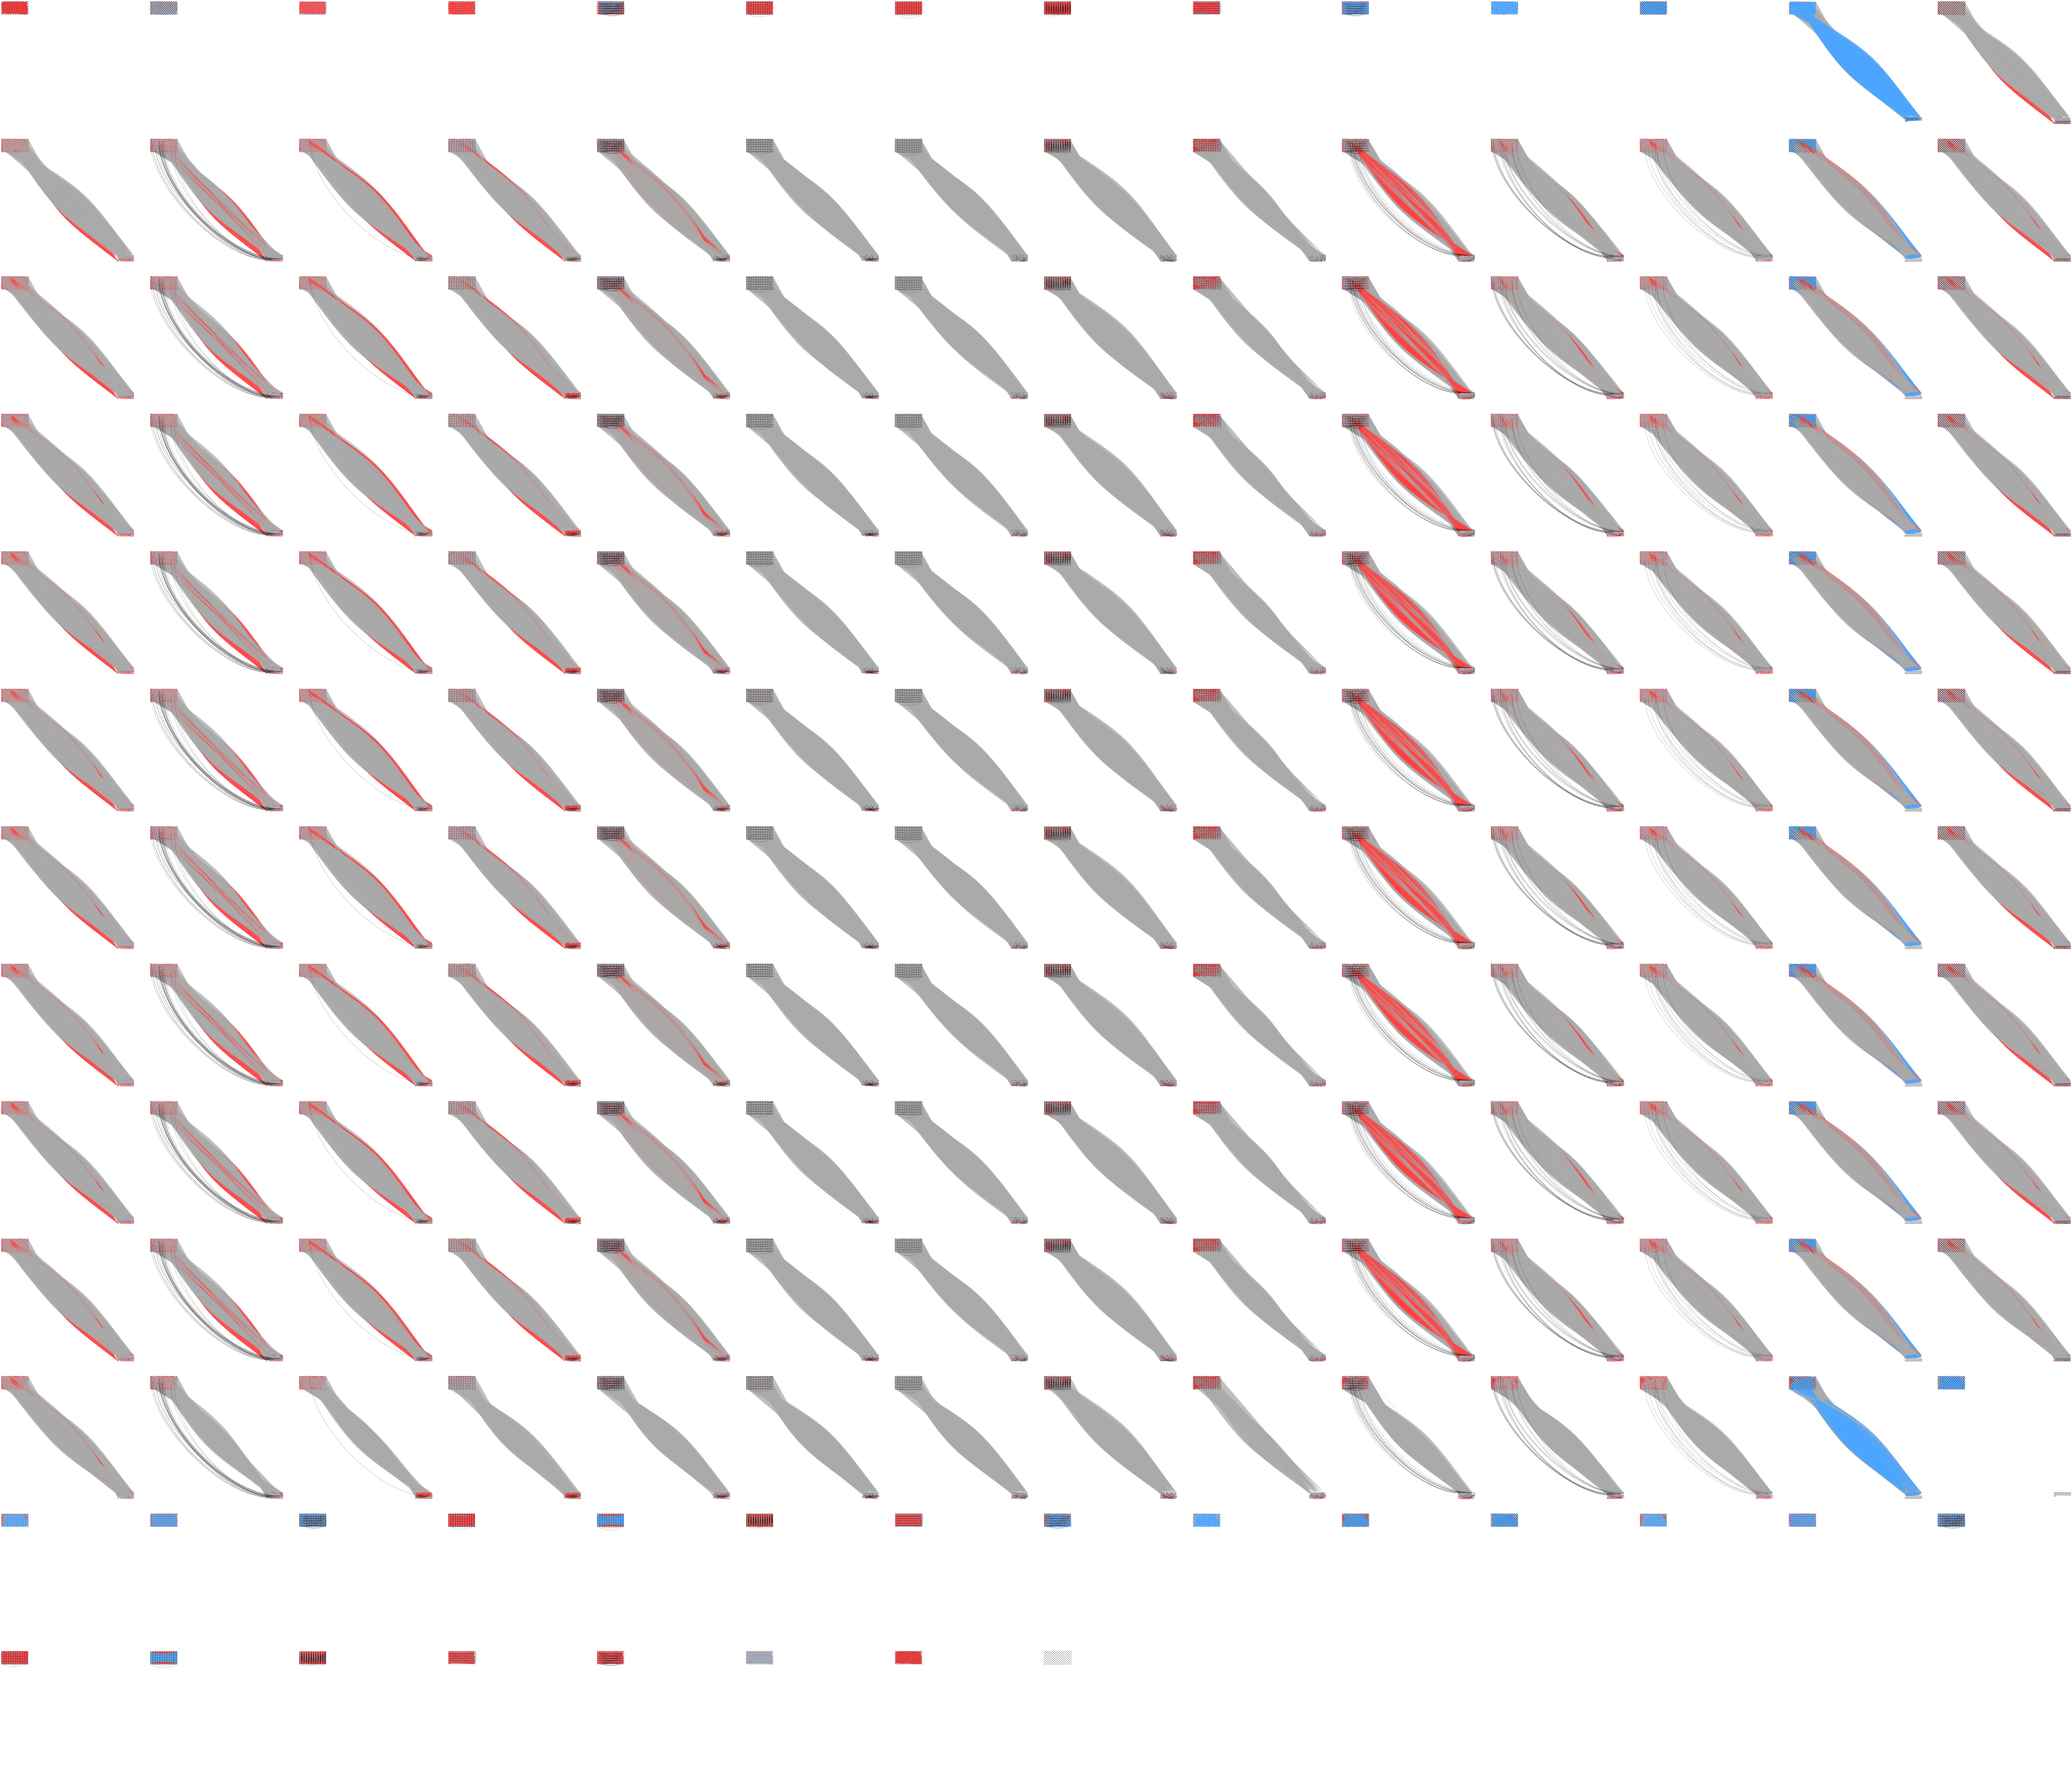

In [6]:
from contextlib import redirect_stdout
from io import StringIO
from zipfile import ZipFile

from IPython.display import Image
from lightstim.protocols.bb_ppm import BBPPMExperiment

experiment = BBPPMExperiment(
    gross, ppm_sequence, plans=plans, rounds=ROUNDS,
    initial_states=INITIAL_STATE, final_measure_states=FINAL_BASIS,
)
with redirect_stdout(StringIO()):
    circuit = experiment.build()
summary = (f"{circuit.num_qubits} physical qubits, {circuit.num_ticks} ticks, "
           f"{circuit.num_detectors} detectors, {circuit.num_observables} observables")
print(summary)
svg = str(circuit.without_noise().diagram("detslice-with-ops-svg"))

# Set to True to display the original vector directly in Jupyter.
INLINE_FULL_SVG = False
preview = f"preview/{hashlib.sha256(svg.encode()).hexdigest()}.png"
with ZipFile(ROOT / "benchmarks/logical_ops/reference/bb_ppm/y1_large_20261124/full_circuit.zip") as archive:
    if not INLINE_FULL_SVG and preview in archive.namelist():
        display(Image(data=archive.read(preview), width=1000))
    else:
        display({"image/svg+xml": svg, "text/plain": summary}, raw=True)

## Cell 5 · Full-Circuit LER with Frozen Relay-BP Parameters (Large-Sample Run)

,Property,Recorded value
0,Target,Y1
1,Physical qubits,378
2,Ticks,175
3,Detectors,2300
4,Observables,11
5,Noise model,circuit_level_with_idling
6,Rounds,10
7,Initial / final basis,X / X
8,Measurement instructions,1
9,Shift instructions,0


,Parameter,Value
0,alpha,0.8
1,gamma0,0.5
2,gamma_dist_interval,"[-0.1, 0.5]"
3,logging,False
4,num_sets,600
5,pre_iter,320
6,seed,0
7,set_max_iter,60
8,stop_nconv,5
9,stopping_criterion,nconv


LER counts any declared LightStim Observable mismatch; nonconvergence is separate.


,p,Shots,Failures,LER (95% CI),Nonconverged,Valid & correct,95% one-sided upper bound
0,5 × 10⁻⁴,1000000,4,[0.04 (+0.0624 / −0.0291)] × 10⁻⁴,50,999950,0.09153 × 10⁻⁴
1,1 × 10⁻³,1000000,19,[0.019 (+0.0107 / −0.00756)] × 10⁻³,280,999719,0.02788 × 10⁻³
2,2 × 10⁻³,100000,116,[1.16 (+0.231 / −0.201)] × 10⁻³,313,99674,1.353 × 10⁻³


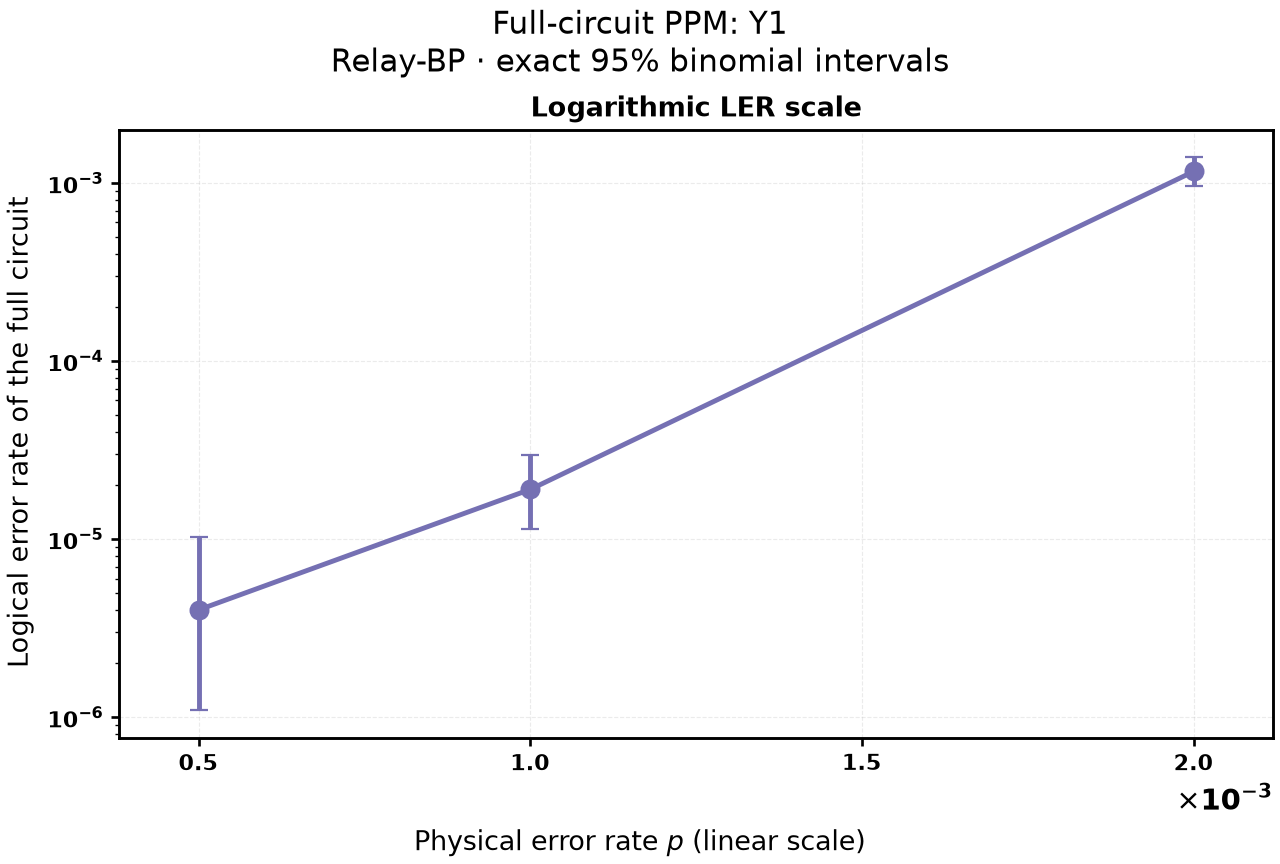

Only completed fixed-N cohorts are shown. Connecting lines guide the eye.
Recorded aggregate results reproduce this table and figure; the original raw-shot archive is not included here.


In [7]:
from benchmarks.logical_ops.plot_bb_ppm import display_results

if RUN_SAMPLING:
    from benchmarks.logical_ops.bb_ppm_runner import run_campaign

    run_campaign(
        sequence=ppm_sequence, plans=plans, p_values=P_VALUES,
        shots=[SHOTS_BY_P[p] for p in P_VALUES], workers=WORKER_PROCESSES,
        run_dir=RUN_DIR, output=RESULTS_PATH, decoder_params=DECODER_PARAMS,
        rounds=ROUNDS, initial_states=INITIAL_STATE, final_measure_states=FINAL_BASIS,
        noise_model=NOISE_MODEL, seed=SAMPLE_SEED, resume=True,
    )

result_view = display_results(
    RESULTS_PATH, expected_plan_sha256=plan_sha256,
    decoder_params=DECODER_PARAMS, shots_by_p=SHOTS_BY_P,
    expected_experiment={
        "rounds": ROUNDS, "initial_state": INITIAL_STATE,
        "final_basis": FINAL_BASIS, "noise_model": NOISE_MODEL,
    },
)
